Celda 1: conecta Google Drive y ubica los 12 CSV mensuales (2025-mes.csv), mostrando su tamaño y ruta para confirmar que están todos.

In [ ]:
# Celda 1: conexión con Drive y búsqueda de los CSV mensuales en la carpeta del proyecto

# Se importan las librerías que se usan para manejar rutas, expresiones regulares y búsqueda de archivos
import os, re, glob

# Se importa el módulo de Colab que permite conectar el entorno con Google Drive
from google.colab import drive

# Se monta Drive en /content/drive; Colab pide autorización la primera vez
drive.mount("/content/drive")

# Se define la carpeta del proyecto, que se asume ubicada directamente en MyDrive
CARPETA = "/content/drive/MyDrive/Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile"

# Se verifica que la carpeta exista; si no, se detiene la ejecución con un mensaje claro
assert os.path.isdir(CARPETA), f"No se encontró la carpeta: {CARPETA}"

# Se define el patrón que debe cumplir el nombre de cada archivo: "2025-" + mes (1 o 2 dígitos) + ".csv"
patron = re.compile(r"2025-(\d{1,2})\.csv")

# Se crea un diccionario donde la clave es el número de mes y el valor es la lista de rutas encontradas
encontrados = {}

# Se recorre la carpeta del proyecto, incluidas sus subcarpetas, buscando archivos "2025-*.csv"
for ruta in glob.glob(CARPETA + "/**/2025-*.csv", recursive=True):
    # Se comprueba que el nombre completo coincida exactamente con el patrón (descarta copias como "2025-1 (1).csv")
    m = patron.fullmatch(os.path.basename(ruta))
    if m:
        # Se guarda la ruta bajo el número de mes; si el mes ya existía, se agrega a su lista
        encontrados.setdefault(int(m.group(1)), []).append(ruta)

# Se revisan los 12 meses en orden para informar cuáles están y cuáles faltan
for mes in range(1, 13):
    rutas = encontrados.get(mes, [])
    # Si no hay ninguna ruta para el mes, se avisa que falta
    if not rutas:
        print(f"mes {mes:2d}: NO ENCONTRADO")
    # Si hay una o más rutas, se imprime el tamaño en MB y la ubicación (más de una indicaría archivos duplicados)
    for r in rutas:
        print(f"mes {mes:2d}: {os.path.getsize(r)/1e6:8.1f} MB  {r}")

MessageError: Error: credential propagation was unsuccessful

Celda 2: define los parámetros del proyecto, crea la carpeta de salida en Drive y verifica en el CSV de enero que tiene 79 columnas y que están las 14 que se van a usar.

In [ ]:
# Celda 2: exploración de las 79 columnas del CSV de enero

# Se importan las librerías necesarias para leer el CSV y mostrar tablas
import csv
import pandas as pd

# Se amplía el límite de tamaño de campo del módulo csv, porque algunos textos son muy largos
csv.field_size_limit(10**9)

# Se configura pandas para mostrar las 79 filas de la tabla, sin recortar texto ni ancho
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 45)

# Se toma la ruta del CSV de enero a partir de lo encontrado en la celda 1
ruta_enero = encontrados[1][0]

# Se define cuántas filas se leen para el análisis (con 100.000 alcanza para conocer cada columna)
N_FILAS = 100_000

# Se abre el CSV con codificación cp1252 y sin transformar los saltos de línea (los respeta el módulo csv)
with open(ruta_enero, encoding="cp1252", errors="replace", newline="") as f:
    # Se crea el lector con ";" como separador y comillas dobles como delimitador de texto
    lector = csv.reader(f, delimiter=";", quotechar='"')
    # Se lee la cabecera, que contiene los nombres de las 79 columnas
    cab = next(lector)
    # Se leen las primeras N_FILAS filas, descartando las que no tengan 79 columnas
    filas = []
    for fila in lector:
        if len(fila) == len(cab):
            filas.append(fila)
        if len(filas) >= N_FILAS:
            break

# Se crea una tabla con las filas leídas, usando los nombres originales como columnas
muestra = pd.DataFrame(filas, columns=cab)
print(f"Columnas: {len(cab)} | filas analizadas: {len(muestra):,}\n")

# Se arma un resumen con una fila por cada columna del archivo
resumen_cols = []
for i, c in enumerate(cab):
    # Se obtiene la columna como texto sin espacios en los extremos
    s = muestra[c].str.strip()
    # Se consideran vacíos tanto la cadena vacía como el texto "NA"
    con_dato = s[(s != "") & (s.str.upper() != "NA")]
    resumen_cols.append({
        # Posición de la columna dentro del archivo
        "pos": i,
        # Nombre original de la columna
        "columna": c,
        # Porcentaje de filas que traen un dato real
        "% con dato": round(100 * len(con_dato) / len(s), 1),
        # Cantidad de valores distintos en la muestra
        "distintos": con_dato.nunique(),
        # Primer valor real encontrado, recortado a 40 caracteres, como ejemplo
        "ejemplo": (con_dato.iloc[0][:40] if len(con_dato) else ""),
    })

# Se muestra la tabla completa, indexada por la posición de la columna
pd.DataFrame(resumen_cols).set_index("pos")

Columnas: 79 | filas analizadas: 100,000



,columna,% con dato,distintos,ejemplo
pos,,,,
0,ID,100.0,40600,47959325
1,Codigo,100.0,40600,1491-43-SE23
2,Link,100.0,40600,http://www.mercadopublico.cl/PurchaseOrd
3,Nombre,100.0,32717,SVC. aseo 2023-2026
4,Descripcion/Obervaciones,100.0,33905,Servicio de aseo para Aeródromo Pichoy d
5,Tipo,100.0,6,SE
6,ProcedenciaOC,100.0,28,Proveniente de licitación pública
7,EsTratoDirecto,100.0,2,No
8,EsCompraAgil,100.0,2,No


Celda 3: cuenta los datos faltantes (vacíos o “NA”) de las 79 columnas en cada uno de los 12 archivos y valida que el número de filas coincida con lo esperado.

In [ ]:
# Celda 3: datos faltantes por columna en cada uno de los 12 archivos

# Se importan las librerías necesarias (por si la celda se ejecuta de forma independiente)
import os, time
import pandas as pd

# Se define la carpeta de salida en Drive, donde se guardará la tabla de resultados
RUTA_SALIDA = CARPETA + "/salida"
os.makedirs(RUTA_SALIDA, exist_ok=True)

# Se define el número de filas esperado por mes (conteo validado previamente con dos métodos distintos)
ESPERADAS = {1: 360196, 2: 354438, 3: 422761, 4: 467436, 5: 437698, 6: 436595,
             7: 453605, 8: 442293, 9: 407358, 10: 466437, 11: 464301, 12: 428049}

# Se crean los contenedores: porcentaje de faltantes por columna y mes, y filas leídas por mes
faltantes_pct = {}
filas_por_mes = {}

# Se recorre cada mes, leyendo el archivo por partes para no llenar la memoria
for mes in range(1, 13):
    # Se anota la hora de inicio del mes para medir cuánto demora
    t0 = time.time()
    # Se inicializan los contadores del mes
    total_filas = 0
    vacios = None

    # Se lee el CSV en bloques de 200.000 filas, todo como texto y sin que pandas convierta "NA" en nulo
    for bloque in pd.read_csv(RUTAS[mes], sep=";", encoding="cp1252", encoding_errors="replace",
                              dtype=str, keep_default_na=False, chunksize=200_000):
        # Se suman las filas del bloque al total del mes
        total_filas += len(bloque)
        # Se cuentan, por columna, las celdas vacías o con el texto "NA"
        v = ((bloque == "") | (bloque == "NA")).sum()
        # Se acumulan los conteos de este bloque con los anteriores
        vacios = v if vacios is None else vacios + v

    # Se convierte el conteo en porcentaje de filas del mes y se guarda
    faltantes_pct[mes] = (100 * vacios / total_filas).round(2)
    filas_por_mes[mes] = total_filas

    # Se compara el número de filas leídas con el esperado y se informa el resultado del mes
    estado = "OK" if total_filas == ESPERADAS[mes] else f"DISTINTO (esperado {ESPERADAS[mes]:,})"
    print(f"mes {mes:2d}: {total_filas:>8,} filas  {estado}  ({time.time() - t0:.0f} s)")

# Se arma la tabla final: una fila por columna, una columna por mes, con el % de datos faltantes
tabla_faltantes = pd.DataFrame(faltantes_pct)
tabla_faltantes.columns = [f"m{m}" for m in tabla_faltantes.columns]

# Se agrega el porcentaje de faltantes sobre las 5 millones de filas, ponderando por el tamaño de cada mes
pesos = pd.Series(filas_por_mes)
pesos.index = tabla_faltantes.columns
tabla_faltantes["TOTAL"] = (tabla_faltantes[pesos.index] * pesos / pesos.sum()).sum(axis=1).round(2)

# Se guarda la tabla en Drive para no tener que recalcularla
tabla_faltantes.to_csv(RUTA_SALIDA + "/faltantes_por_columna_y_mes.csv")

# Se muestran solo las columnas que tienen algún dato faltante en algún mes, ordenadas de más a menos faltantes
con_faltantes = tabla_faltantes[tabla_faltantes.drop(columns="TOTAL").max(axis=1) > 0]
print(f"\nColumnas con algún dato faltante: {len(con_faltantes)} de {len(tabla_faltantes)}")
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 250)
con_faltantes.sort_values("TOTAL", ascending=False)

mes  1:  360,196 filas  OK  (21 s)
mes  2:  354,438 filas  OK  (22 s)
mes  3:  422,761 filas  OK  (26 s)
mes  4:  467,436 filas  OK  (29 s)
mes  5:  437,698 filas  OK  (27 s)
mes  6:  436,595 filas  OK  (28 s)
mes  7:  453,605 filas  OK  (29 s)
mes  8:  442,293 filas  OK  (28 s)
mes  9:  407,358 filas  OK  (24 s)
mes 10:  466,437 filas  OK  (29 s)
mes 11:  464,301 filas  OK  (29 s)
mes 12:  428,049 filas  OK  (27 s)

Columnas con algún dato faltante: 32 de 79


,m1,m2,m3,m4,m5,m6,m7,m8,m9,m10,m11,m12,TOTAL
FechaCancelacion,100.00,99.99,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
Codigo_ConvenioMarco,82.85,85.23,84.93,85.63,86.18,86.25,86.08,85.83,85.68,85.06,85.56,86.33,85.51
CodigoLicitacion,60.52,64.70,67.34,66.88,65.93,65.06,65.06,65.35,65.29,66.15,66.62,64.40,65.37
PaisProveedor,43.54,51.20,53.47,54.08,54.03,53.07,53.23,53.48,53.38,53.97,54.41,53.47,52.79
totalImpuestos,38.12,45.64,48.25,48.96,48.81,48.11,48.80,49.08,49.00,49.38,50.25,48.76,47.97
CodigoProyectoPlanAnualCompras,69.76,40.24,37.71,38.19,37.88,38.87,39.93,39.63,41.05,43.05,43.69,46.50,42.67
Financiamiento,48.89,42.18,41.70,38.33,37.61,37.34,37.49,36.06,35.38,34.82,32.82,34.68,37.84
EspecificacionProveedor,25.97,31.86,33.79,34.47,34.51,34.23,34.42,35.29,34.36,35.67,37.14,35.42,34.11
EsTratoDirecto,0.00,0.00,0.00,0.00,0.00,13.35,43.45,43.80,44.32,45.14,45.78,44.07,24.15
ProcedenciaOC,0.00,0.00,0.00,0.00,0.00,13.35,43.45,43.80,44.32,45.14,45.78,44.07,24.15


Celda 4: clasifica cada columna como constante dentro de la orden o variable entre sus ítems, muestra las categorías clave y comprueba si FechaSolicitudCancelacion sirve realmente para detectar cancelaciones.

In [ ]:
# Celda 4: columnas de nivel orden vs. nivel ítem, categorías clave y revisión de FechaSolicitudCancelacion

# Se cuenta, para cada columna, cuántos valores distintos tiene dentro de cada orden
# (se usa la tabla "muestra" con las primeras 100.000 filas de enero, creada en la celda 2)
distintos_por_orden = muestra.groupby("Codigo").nunique(dropna=False)

# Se calcula cuántas órdenes tienen más de un valor distinto en cada columna
ordenes_que_varian = (distintos_por_orden > 1).sum()
total_ordenes = len(distintos_por_orden)

# Se arma la tabla de resultados, con el porcentaje de órdenes donde la columna cambia entre ítems
tabla = pd.DataFrame({
    "ordenes_donde_varia": ordenes_que_varian,
    "% ordenes donde varia": (100 * ordenes_que_varian / total_ordenes).round(1),
})
# Se clasifica cada columna: "orden" si nunca cambia dentro de una orden, "ítem" si cambia en alguna
tabla["nivel"] = np.where(tabla.ordenes_donde_varia == 0, "orden", "ítem")

print(f"Órdenes en la muestra: {total_ordenes:,}")
print(f"Columnas constantes dentro de la orden: {(tabla.nivel == 'orden').sum()} | variables entre ítems: {(tabla.nivel == 'ítem').sum()}")
print("\nColumnas de nivel ÍTEM (cambian dentro de una misma orden):")
print(tabla[tabla.nivel == "ítem"].sort_values("% ordenes donde varia", ascending=False).to_string())

# Se toma una fila por orden para contar categorías sin repetir órdenes
por_orden = muestra.drop_duplicates("Codigo")

# Se muestran las categorías y su frecuencia para las columnas de modalidad de compra, estado, moneda y sector
print()
for c in ["Tipo", "EsTratoDirecto", "EsCompraAgil", "ProcedenciaOC", "Estado", "EstadoProveedor", "TipoMonedaOC", "sector"]:
    vc = por_orden[c].value_counts()
    print(f"--- {c} ({len(vc)} categorías)")
    print(vc.head(12).to_string(), "\n")

# Se revisa si FechaSolicitudCancelacion indica realmente una cancelación:
# se calcula, por estado, qué porcentaje de órdenes tiene esa fecha igual a FechaEnvio
print("--- FechaSolicitudCancelacion según el estado de la orden")
rev = por_orden.assign(igual_a_envio=(por_orden["FechaSolicitudCancelacion"] == por_orden["FechaEnvio"]),
                       con_fecha=~por_orden["FechaSolicitudCancelacion"].isin(["", "NA"]))
print(rev.groupby("Estado").agg(ordenes=("Codigo", "size"),
                                 pct_con_fecha=("con_fecha", lambda s: round(100 * s.mean(), 1)),
                                 pct_igual_a_FechaEnvio=("igual_a_envio", lambda s: round(100 * s.mean(), 1))).to_string())

Órdenes en la muestra: 40,600
Columnas constantes dentro de la orden: 61 | variables entre ítems: 17

Columnas de nivel ÍTEM (cambian dentro de una misma orden):
                         ordenes_donde_varia  % ordenes donde varia nivel
IDItem                                 12720                   31.3  ítem
EspecificacionComprador                11846                   29.2  ítem
totalLineaNeto                         11795                   29.1  ítem
precioNeto                             10994                   27.1  ítem
EspecificacionProveedor                10007                   24.6  ítem
cantidad                                9620                   23.7  ítem
NombreroductoGenerico                   4435                   10.9  ítem
codigoProductoONU                       2888                    7.1  ítem
Categoria                               2561                    6.3  ítem
RubroN3                                 2561                    6.3  ítem
codigoCategoria         

Celda 5: define los parámetros, las columnas finales y la función que convierte ítems en órdenes y arma la tabla proveedor × rubro, y las prueba con enero.

In [ ]:
# Celda 5: parámetros, columnas finales y función de lectura (ítems -> órdenes), probada con enero

# Se importan las librerías que usa esta celda (por si se ejecuta de forma independiente)
import os, csv, html, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Se amplía el límite de tamaño de campo del módulo csv, porque algunos textos son muy largos
csv.field_size_limit(10**9)

# ------------------------- PARÁMETROS DEL PROYECTO -------------------------

# Se define la carpeta de salida en Drive y se crea si no existe
RUTA_SALIDA = CARPETA + "/salida"
os.makedirs(RUTA_SALIDA, exist_ok=True)

# Se arma un diccionario mes -> ruta del CSV, usando lo encontrado en la celda 1
RUTAS = {mes: encontrados[mes][0] for mes in range(1, 13)}

# Se define el monto (en pesos) desde el cual una orden en moneda distinta de CLP se considera sospechosa
UMBRAL_MONTO_SOSPECHOSO = 1e11

# Se define el estado de orden que se excluye de los rankings (el comprador pidió cancelarla)
ESTADOS_EXCLUIDOS = {"Cancelacion solicitada"}

# Se define el RUT numérico bajo el cual el proveedor se considera persona natural
RUT_MAX_PERSONA_NATURAL = 50_000_000

# Se define el tamaño de la muestra para desarrollar en el clúster y la semilla (el número de grupo)
MUESTRA_N = 10_000
SEED = 13

# ------------------------- COLUMNAS FINALES -------------------------

# Se define la correspondencia entre el nombre en el proyecto y la columna del CSV (todas de nivel orden)
COLUMNAS = {
    "codigo": "Codigo", "fecha_envio": "FechaEnvio", "fecha_creacion": "FechaCreacion",
    "fecha_aceptacion": "FechaAceptacion", "estado": "Estado", "estado_proveedor": "EstadoProveedor",
    "tipo": "Tipo", "procedencia": "ProcedenciaOC", "cod_licitacion": "CodigoLicitacion",
    "cod_convenio_marco": "Codigo_ConvenioMarco", "moneda": "TipoMonedaOC", "monto_original": "MontoTotalOC",
    "monto_clp": "MontoTotalOC_PesosChilenos", "cod_organismo": "CodigoOrganismoPublico",
    "organismo": "OrganismoPublico", "sector": "sector", "region_comprador": "RegionUnidadCompra",
    "cod_proveedor": "CodigoProveedor", "rut_proveedor": "RutSucursal", "nombre_proveedor": "NombreProveedor",
    "region_proveedor": "RegionProveedor", "actividad_proveedor": "ActividadProveedor",
}

# Se definen las columnas de nivel ítem que se usan solo para la tabla proveedor x rubro
COL_ITEM = {"rubro": "RubroN1", "monto_item": "totalLineaNeto", "moneda_item": "monedaItem"}

# Se define el conjunto de campos que deberían ser idénticos entre los ítems de una misma orden
CONSISTENTES = ["monto_clp", "cod_proveedor", "cod_organismo", "estado"]

# ------------------------- FUNCIONES -------------------------

# Se define la función que normaliza cualquier texto antes de guardarlo
def limpiar_texto(s):
    # Se convierten las entidades HTML a su carácter real (por ejemplo "&amp;" pasa a "&")
    s = html.unescape(s)
    # Se reemplazan tabuladores y saltos de línea por espacios, porque romperían el TSV de salida
    s = s.replace("\t", " ").replace("\r", " ").replace("\n", " ")
    # Se reemplazan comillas dobles y barras invertidas, que también pueden romper el formato
    s = s.replace('"', "'").replace("\\", "/")
    # Se colapsan los espacios repetidos y se eliminan los de los extremos
    s = " ".join(s.split())
    # Se transforma el texto "NA" (valor vacío en el origen) en una cadena vacía
    return "" if s.upper() == "NA" else s

# Se define la función que lee un CSV mensual y devuelve: tabla de órdenes, tabla proveedor x rubro y resumen
def leer_mes(ruta, mes):
    # Se anota la hora de inicio para medir cuánto demora el mes
    t0 = time.time()
    # Se crean los contenedores: órdenes por código, acumulado proveedor x rubro y contadores de control
    ordenes, rubros, filas, malas, conflictos = {}, {}, 0, 0, 0

    # Se abre el CSV con codificación cp1252 y sin transformar saltos de línea (los respeta el módulo csv)
    with open(ruta, encoding="cp1252", errors="replace", newline="") as f:
        lector = csv.reader(f, delimiter=";", quotechar='"')
        # Se lee la cabecera y se verifica que tenga las 79 columnas esperadas
        cab = next(lector)
        assert len(cab) == 79, f"mes {mes}: se esperaban 79 columnas y hay {len(cab)}"
        # Se calcula la posición de cada columna de orden y de ítem dentro de la fila
        pos = {nuevo: cab.index(orig) for nuevo, orig in COLUMNAS.items()}
        pit = {nuevo: cab.index(orig) for nuevo, orig in COL_ITEM.items()}

        # Se recorre cada fila del archivo (cada fila es un ítem de una orden)
        for fila in lector:
            filas += 1
            # Si la fila no tiene 79 columnas, se cuenta como malformada y se omite
            if len(fila) != len(cab):
                malas += 1
                continue

            # --- parte de ítem: se acumula el monto neto por (proveedor, rubro) solo para ítems en pesos
            if fila[pit["moneda_item"]] == "CLP":
                try:
                    monto = float(fila[pit["monto_item"]].replace(",", "."))
                    llave = (fila[pos["cod_proveedor"]], limpiar_texto(fila[pit["rubro"]]) or "(sin rubro)")
                    acum = rubros.setdefault(llave, [0.0, 0])
                    acum[0] += monto
                    acum[1] += 1
                except ValueError:
                    pass

            # --- parte de orden: se guarda la primera fila de cada orden y se cuentan sus ítems
            cod = fila[pos["codigo"]]
            o = ordenes.get(cod)
            if o is None:
                # Primer ítem de la orden: se guardan los datos limpios, el contador en 1 y los campos a verificar
                ordenes[cod] = [{k: limpiar_texto(fila[i]) for k, i in pos.items()}, 1,
                                [fila[pos[k]] for k in CONSISTENTES]]
            else:
                # Ítem adicional: se suma al contador y se verifica que los campos clave no cambien
                o[1] += 1
                if [fila[pos[k]] for k in CONSISTENTES] != o[2]:
                    conflictos += 1

    # Se arma la tabla de órdenes (una fila por orden) con el mes y el número de ítems
    d = pd.DataFrame([v[0] | {"n_items": v[1]} for v in ordenes.values()])
    d.insert(1, "mes", mes)
    # Se arma la tabla proveedor x rubro del mes
    r = pd.DataFrame([(k[0], k[1], v[0], v[1]) for k, v in rubros.items()],
                     columns=["cod_proveedor", "rubro", "monto_neto_clp", "n_items"])
    # Se arma el resumen del mes con los contadores de control
    info = {"mes": mes, "lineas": filas, "lineas_malformadas": malas, "ordenes": len(d),
            "items_con_datos_distintos": conflictos, "segundos": round(time.time() - t0, 1)}
    return d, r, info

# ------------------------- PRUEBA CON ENERO -------------------------

# Se procesa solo el mes 1 para comprobar que todo funciona y medir el tiempo
d1, r1, info1 = leer_mes(RUTAS[1], 1)

# Se muestra el resumen de control (se esperan 360.196 líneas, 139.431 órdenes, 0 malformadas y 0 conflictos)
print(info1)
print("\nTabla de órdenes:", d1.shape, "| tabla proveedor x rubro:", r1.shape)
print("\nÓrdenes (primeras filas):")
display(d1.head(3).T)
print("Proveedor x rubro (los 5 de mayor monto):")
display(r1.sort_values("monto_neto_clp", ascending=False).head(5))

{'mes': 1, 'lineas': 360196, 'lineas_malformadas': 0, 'ordenes': 139431, 'items_con_datos_distintos': 0, 'segundos': 25.2}

Tabla de órdenes: (139431, 24) | tabla proveedor x rubro: (42050, 4)

Órdenes (primeras filas):


,0,1,2
codigo,1491-43-SE23,1021609-108-SE23,2702-389-SE23
mes,1,1,1
fecha_envio,2025-01-14,2025-01-21,2025-01-21
fecha_creacion,2023-04-18,2023-06-30,2023-07-18
fecha_aceptacion,2025-01-15,2025-01-21,2025-01-22
estado,Recepcion Conforme,Aceptada,Aceptada
estado_proveedor,Recepcion Conforme,Aceptada,Aceptada
tipo,SE,SE,SE
procedencia,Proveniente de licitación pública,Proveniente de licitación pública,Proveniente de licitación pública
cod_licitacion,1491-5-LP23,1021609-9-LQ23,2702-15-LE23


Proveedor x rubro (los 5 de mayor monto):


,cod_proveedor,rubro,monto_neto_clp,n_items
33583,97685,"Organizaciones y consultorías políticas, ...",2.054720e+11,2
32094,83487,"Organizaciones y consultorías políticas, ...",2.010542e+11,6
32028,27324,"Organizaciones y consultorías políticas, ...",1.779779e+11,4
13355,68073,Servicios de construcción y mantenimiento,1.305729e+11,2
3966,22259,"Organizaciones y consultorías políticas, ...",1.101234e+11,5


Celda 6: lee los 12 meses, une todo en una sola tabla, verifica los conteos, convierte los montos y guarda una copia intermedia en Drive.

In [ ]:
# Celda 6: lectura de los 12 meses, validación y copia intermedia en Drive

# Se define el número de órdenes esperado por mes (obtenido antes con otro método de lectura)
ORDENES_ESPERADAS = {1: 139431, 2: 126153, 3: 148998, 4: 161770, 5: 156808, 6: 155260,
                     7: 164088, 8: 159540, 9: 150014, 10: 170505, 11: 168205, 12: 155266}

# Se crean las listas donde se acumulará el resultado de cada mes
partes_ordenes, partes_rubros, resumen = [], [], []

# Se procesa cada mes y se informa el avance, comparando con lo esperado
for mes in range(1, 13):
    d, r, info = leer_mes(RUTAS[mes], mes)
    partes_ordenes.append(d)
    partes_rubros.append(r)
    resumen.append(info)
    # Se verifica que líneas y órdenes coincidan con los valores esperados
    ok = (info["lineas"] == ESPERADAS[mes]) and (info["ordenes"] == ORDENES_ESPERADAS[mes])
    print(f"mes {mes:2d}: {info['lineas']:>8,} líneas -> {info['ordenes']:>8,} órdenes  "
          f"{'OK' if ok else 'REVISAR'}  ({info['segundos']} s)")

# Se unen los 12 meses en una sola tabla de órdenes y se libera la memoria de las partes
df = pd.concat(partes_ordenes, ignore_index=True)
del partes_ordenes

# Se unen las tablas proveedor x rubro y se suman los montos de un mismo par entre meses
rubros = (pd.concat(partes_rubros, ignore_index=True)
            .groupby(["cod_proveedor", "rubro"], as_index=False)
            .agg(monto_neto_clp=("monto_neto_clp", "sum"), n_items=("n_items", "sum")))
del partes_rubros

# Se arma la tabla resumen por mes
resumen = pd.DataFrame(resumen).set_index("mes")
resumen["items_por_orden"] = (resumen.lineas / resumen.ordenes).round(2)

# ------------------------- VALIDACIONES -------------------------

# Se comprueba que no haya filas malformadas ni ítems con datos clave distintos dentro de una orden
assert resumen.lineas_malformadas.sum() == 0, "hay filas con distinto número de columnas"
assert resumen.items_con_datos_distintos.sum() == 0, "hay ítems con datos distintos dentro de una orden"
# Se comprueba que ninguna orden aparezca en más de un mes
assert df.codigo.is_unique, "hay órdenes repetidas entre meses"

print(f"\nTOTAL: {resumen.lineas.sum():,} líneas (ítems) -> {len(df):,} órdenes distintas")
print("Órdenes repetidas entre meses: 0 | ítems con datos distintos: 0 | filas malformadas: 0")

# ------------------------- CONVERSIÓN DE MONTOS -------------------------

# Se convierten los montos a número, cambiando la coma decimal por punto
for c in ("monto_clp", "monto_original"):
    df[c] = pd.to_numeric(df[c].str.replace(",", ".", regex=False), errors="coerce")
print("Montos que no se pudieron convertir a número:", int(df.monto_clp.isna().sum() + df.monto_original.isna().sum()))

# Se convierten a tipo "category" las columnas con pocos valores distintos, para ahorrar memoria
for c in ["estado", "estado_proveedor", "tipo", "procedencia", "moneda", "sector", "region_comprador",
          "region_proveedor", "actividad_proveedor", "organismo", "cod_organismo",
          "nombre_proveedor", "cod_proveedor", "rut_proveedor"]:
    df[c] = df[c].astype("category")
print(f"Memoria de la tabla de órdenes: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

# ------------------------- COPIA INTERMEDIA EN DRIVE -------------------------

# Se guarda una copia comprimida para no tener que releer los 12 CSV si la sesión de Colab se reinicia
try:
    df.to_parquet(RUTA_SALIDA + "/intermedio_ordenes.parquet", index=False)
    rubros.to_parquet(RUTA_SALIDA + "/intermedio_proveedor_rubro.parquet", index=False)
    print("Copia intermedia guardada en:", RUTA_SALIDA)
except Exception as e:
    print("No se pudo guardar la copia intermedia:", e)

# Se muestra el resumen por mes
resumen

mes  1:  360,196 líneas ->  139,431 órdenes  OK  (27.2 s)
mes  2:  354,438 líneas ->  126,153 órdenes  OK  (23.1 s)
mes  3:  422,761 líneas ->  148,998 órdenes  OK  (29.6 s)
mes  4:  467,436 líneas ->  161,770 órdenes  OK  (32.0 s)
mes  5:  437,698 líneas ->  156,808 órdenes  OK  (29.8 s)
mes  6:  436,595 líneas ->  155,260 órdenes  OK  (29.8 s)
mes  7:  453,605 líneas ->  164,088 órdenes  OK  (30.8 s)
mes  8:  442,293 líneas ->  159,540 órdenes  OK  (29.4 s)
mes  9:  407,358 líneas ->  150,014 órdenes  OK  (28.1 s)
mes 10:  466,437 líneas ->  170,505 órdenes  OK  (31.8 s)
mes 11:  464,301 líneas ->  168,205 órdenes  OK  (31.4 s)
mes 12:  428,049 líneas ->  155,266 órdenes  OK  (28.4 s)

TOTAL: 5,141,167 líneas (ítems) -> 1,856,038 órdenes distintas
Órdenes repetidas entre meses: 0 | ítems con datos distintos: 0 | filas malformadas: 0
Montos que no se pudieron convertir a número: 0
Memoria de la tabla de órdenes: 0.77 GB
Copia intermedia guardada en: /content/drive/MyDrive/Proyecto Gru

,lineas,lineas_malformadas,ordenes,items_con_datos_distintos,segundos,items_por_orden
mes,,,,,,
1,360196,0,139431,0,27.2,2.58
2,354438,0,126153,0,23.1,2.81
3,422761,0,148998,0,29.6,2.84
4,467436,0,161770,0,32.0,2.89
5,437698,0,156808,0,29.8,2.79
6,436595,0,155260,0,29.8,2.81
7,453605,0,164088,0,30.8,2.76
8,442293,0,159540,0,29.4,2.77
9,407358,0,150014,0,28.1,2.72


Celda 7: revisa los montos. Muestra su distribución, los factores de conversión de las monedas y las órdenes más grandes, para decidir el umbral de las órdenes sospechosas.

Monto por orden (CLP):
count             1,856,038
mean             24,675,037
std          13,372,635,533
min                      -1
50%                 870,584
90%               6,949,600
99%              82,772,617
99.9%           800,287,217
max      15,744,671,499,995

Órdenes con monto <= 0: 1 | con monto <= 100 pesos: 2994

Factor de conversión implícito (pesos por unidad, mediana):
moneda
CLF    39192.0
EUR     1093.0
USD      946.0
UTM    68785.0


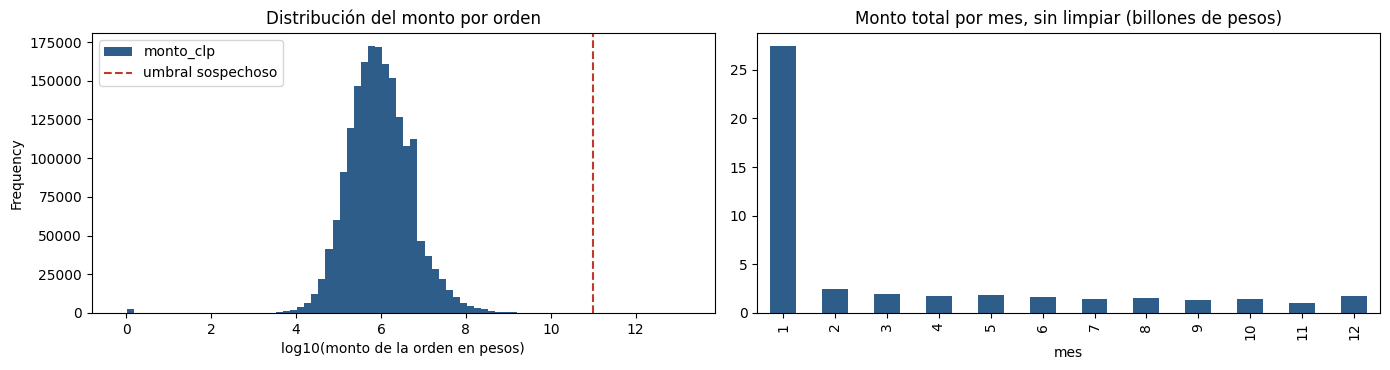

Las 15 órdenes más grandes:


,codigo,mes,estado,moneda,monto_original,monto_clp,organismo,nombre_proveedor
35800,2560-3-SE25,1,Aceptada,UTM,"233,500,000","15,744,671,499,995",I MUNICIPALIDAD DE LAS CONDES,SCP
6318,2667-1450-SE24,1,Cancelacion solicitada,UTM,"135,129,195","9,093,384,018,048",I MUNICIPALIDAD DE VITACURA,RAINDROP LTDA.
141182,85-429-SE24,2,Recepcion Conforme,CLP,"403,570,899,169","403,570,899,169",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,EDENRED CHILE SOCIEDAD ANONIMA
718593,2667-413-SE25,5,Aceptada,UTM,"5,708,406","391,870,668,818",I MUNICIPALIDAD DE VITACURA,Servicios Multitécnicos Sinergia Ltda.
416045,85-98-SE25,4,Aceptada,CLP,"314,396,802,821","314,396,802,821",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,MARCO ANTONIO
871442,1395481-9-SE25,6,Aceptada,CLF,"7,278,624","285,696,028,540",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,BCI SEGUROS VIDA S A
141181,85-428-SE24,2,Recepcion Conforme,CLP,"252,806,363,831","252,806,363,831",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,SODEXO SOLUCIONES DE MOTIVACION CHILE S.A.
106468,85-43-SE25,1,Enviada a proveedor,CLP,"244,511,699,289","244,511,699,289",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
269953,85-87-SE25,3,Aceptada,CLP,"235,457,183,114","235,457,183,114",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
862331,1186229-166-SE25,6,Recepcion Conforme,CLP,"229,220,958,511","229,220,958,511",SERVICIO DE REGISTRO CIVIL E IDENTIFICACION,IDEMIA IDENTITY & SECURITY CHILE



Órdenes en otra moneda con monto >= 100,000,000,000 pesos: 12
Suman 27.11 billones de 45.80 (59.2 %)

Para revisar a mano: 20 órdenes en otra moneda entre 10.000 y 100.000 millones de pesos


,codigo,mes,estado,moneda,monto_original,monto_clp,organismo,nombre_proveedor
267776,85-67-SE25,3,Recepcion Conforme,USD,"37,216,141","36,736,796,724",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,NET NOW S.A.
1094810,4127-301-SE25,8,Recepcion Conforme,USD,"37,327,324","35,993,993,082",SUBSECRETARIA DE SALUD PUBLICA,HP INC CHILE COMERCIAL LIMITADA
910246,4707-257-SE25,7,Aceptada,CLF,"833,000","32,711,652,941",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1844,2667-1237-SE24,1,Aceptada,UTM,"490,623","32,656,334,094",I MUNICIPALIDAD DE VITACURA,STARCO S A
766167,4707-203-SE25,6,Aceptada,CLF,"833,000","32,651,127,031",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1124819,4707-305-SE25,8,Aceptada,CLF,"833,000","32,617,013,078",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
598050,4707-160-SE25,5,Aceptada,CLF,"833,000","32,571,464,898",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
445653,4707-121-SE25,4,Aceptada,CLF,"833,000","32,407,139,379",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1696405,2560-105-SE25,11,Aceptada,UTM,"406,089","28,240,225,715",I MUNICIPALIDAD DE LAS CONDES,BITACORA
1535463,2560-81-SE25,11,Aceptada,UTM,"403,187","27,926,760,064",I MUNICIPALIDAD DE LAS CONDES,BITACORA



Órdenes EN PESOS >= 100,000,000,000: 12


,codigo,mes,estado,moneda,monto_original,monto_clp,organismo,nombre_proveedor
141182,85-429-SE24,2,Recepcion Conforme,CLP,"403,570,899,169","403,570,899,169",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,EDENRED CHILE SOCIEDAD ANONIMA
416045,85-98-SE25,4,Aceptada,CLP,"314,396,802,821","314,396,802,821",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,MARCO ANTONIO
141181,85-428-SE24,2,Recepcion Conforme,CLP,"252,806,363,831","252,806,363,831",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,SODEXO SOLUCIONES DE MOTIVACION CHILE S.A.
106468,85-43-SE25,1,Enviada a proveedor,CLP,"244,511,699,289","244,511,699,289",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
269953,85-87-SE25,3,Aceptada,CLP,"235,457,183,114","235,457,183,114",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
862331,1186229-166-SE25,6,Recepcion Conforme,CLP,"229,220,958,511","229,220,958,511",SERVICIO DE REGISTRO CIVIL E IDENTIFICACION,IDEMIA IDENTITY & SECURITY CHILE
106455,85-37-SE25,1,Aceptada,CLP,"211,461,702,288","211,461,702,288",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,SERVICIOS ALIMENTICIOS HENDAYA SAC
106471,85-45-SE25,1,Aceptada,CLP,"207,355,546,556","207,355,546,556",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,sosersa
269957,85-97-SE25,3,Aceptada,CLP,"197,947,084,476","197,947,084,476",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,sosersa
269955,85-89-SE25,3,Aceptada,CLP,"193,037,661,793","193,037,661,793",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,COMERCIAL DE ALIMENTOS SOCIEDAD ANONIMA


In [ ]:
# Celda 7: revisión de los montos (distribución, conversión de monedas y órdenes extremas)

# Se resumen estadísticamente los montos por orden en pesos chilenos, con formato de miles
print("Monto por orden (CLP):")
print(df.monto_clp.describe(percentiles=[.5, .9, .99, .999]).apply(lambda v: f"{v:,.0f}").to_string())

# Se cuentan las órdenes con montos inválidos o muy bajos
print(f"\nÓrdenes con monto <= 0: {(df.monto_clp <= 0).sum()} | con monto <= 100 pesos: {(df.monto_clp <= 100).sum()}")

# Se estima el factor de conversión de cada moneda: pesos por unidad de la moneda original (mediana)
no_clp = df[(df.moneda != "CLP") & (df.monto_original > 0)]
factor = (no_clp.monto_clp / no_clp.monto_original).groupby(no_clp.moneda, observed=True).median().round(0)
print("\nFactor de conversión implícito (pesos por unidad, mediana):")
print(factor.to_string())

# Se dibujan la distribución de los montos (escala logarítmica) y el monto total por mes
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
np.log10(df.monto_clp[df.monto_clp > 0]).plot.hist(bins=80, ax=ax[0], color="#2f5d8a")
ax[0].axvline(np.log10(UMBRAL_MONTO_SOSPECHOSO), color="#c0392b", ls="--", label="umbral sospechoso")
ax[0].set_xlabel("log10(monto de la orden en pesos)")
ax[0].set_title("Distribución del monto por orden")
ax[0].legend()
(df.groupby("mes").monto_clp.sum() / 1e12).plot.bar(ax=ax[1], color="#2f5d8a")
ax[1].set_title("Monto total por mes, sin limpiar (billones de pesos)")
ax[1].set_xlabel("mes")
plt.tight_layout()
plt.show()

# Se define una función para mostrar tablas de órdenes con los montos con separador de miles
cols = ["codigo", "mes", "estado", "moneda", "monto_original", "monto_clp", "organismo", "nombre_proveedor"]
def formatear(t):
    return t.assign(monto_original=t.monto_original.map("{:,.0f}".format),
                    monto_clp=t.monto_clp.map("{:,.0f}".format))

# Se muestran las 15 órdenes más grandes, sea cual sea su moneda
print("Las 15 órdenes más grandes:")
display(formatear(df.nlargest(15, "monto_clp")[cols]))

# Se muestran las órdenes en OTRA moneda que superan el umbral (las que se marcarían como sospechosas)
sosp = df[(df.moneda != "CLP") & (df.monto_clp >= UMBRAL_MONTO_SOSPECHOSO)].sort_values("monto_clp", ascending=False)
print(f"\nÓrdenes en otra moneda con monto >= {UMBRAL_MONTO_SOSPECHOSO:,.0f} pesos: {len(sosp)}")
print(f"Suman {sosp.monto_clp.sum()/1e12:.2f} billones de {df.monto_clp.sum()/1e12:.2f} ({100*sosp.monto_clp.sum()/df.monto_clp.sum():.1f} %)")

# Se muestran las órdenes en otra moneda entre 10.000 y 100.000 millones, para revisarlas a mano (no se excluirían)
cerca = df[(df.moneda != "CLP") & (df.monto_clp >= 1e10) & (df.monto_clp < UMBRAL_MONTO_SOSPECHOSO)]
print(f"\nPara revisar a mano: {len(cerca)} órdenes en otra moneda entre 10.000 y 100.000 millones de pesos")
display(formatear(cerca.sort_values("monto_clp", ascending=False)[cols]).head(15))

# Se muestran las órdenes EN PESOS por sobre 100.000 millones, que no se marcarían pero conviene conocer
clp_grandes = df[(df.moneda == "CLP") & (df.monto_clp >= UMBRAL_MONTO_SOSPECHOSO)].sort_values("monto_clp", ascending=False)
print(f"\nÓrdenes EN PESOS >= {UMBRAL_MONTO_SOSPECHOSO:,.0f}: {len(clp_grandes)}")
display(formatear(clp_grandes[cols]).head(15))

Celda 8: lee las líneas de ítem de las 32 órdenes sospechosas (las 12 sobre el umbral y las 20 de la banda intermedia) y compara el monto de la cabecera con la suma de sus líneas. También revisa las órdenes de monto simbólico.

In [ ]:
# Celda 8: revisión de las líneas de ítem de las órdenes sospechosas y de los montos simbólicos

# Se juntan los códigos de las órdenes sospechosas (celda 7): las de otra moneda sobre el umbral y las de la banda intermedia
codigos = set(sosp.codigo) | set(cerca.codigo)
print(f"Órdenes a revisar: {len(codigos)}")

# Se definen las columnas que se leen de cada CSV (leer solo estas acelera mucho la lectura)
COLS_REV = ["Codigo", "TipoMonedaOC", "MontoTotalOC", "MontoTotalOC_PesosChilenos", "TotalNetoOC",
            "monedaItem", "cantidad", "precioNeto", "totalLineaNeto"]

# Se recorren los 12 meses y se guardan solo las filas (ítems) de esas órdenes
partes = []
for mes in range(1, 13):
    for bloque in pd.read_csv(RUTAS[mes], sep=";", encoding="cp1252", encoding_errors="replace",
                              dtype=str, keep_default_na=False, usecols=COLS_REV, chunksize=300_000):
        # Se filtran las filas cuyo código está en la lista a revisar
        sel = bloque[bloque.Codigo.isin(codigos)]
        if len(sel):
            partes.append(sel)
    print(f"mes {mes:2d} revisado", end=" | ")
it = pd.concat(partes, ignore_index=True)

# Se convierten a número las columnas de montos, cambiando la coma decimal por punto
for c in ["MontoTotalOC", "MontoTotalOC_PesosChilenos", "TotalNetoOC", "cantidad", "precioNeto", "totalLineaNeto"]:
    it[c] = pd.to_numeric(it[c].str.replace(",", ".", regex=False), errors="coerce")

# Se arma un resumen por orden: moneda de la cabecera, moneda de los ítems y suma de las líneas
res = it.groupby("Codigo").agg(
    moneda_orden=("TipoMonedaOC", "first"),
    monedas_items=("monedaItem", lambda s: "/".join(sorted(set(s)))),
    n_items=("totalLineaNeto", "size"),
    monto_orden=("MontoTotalOC", "first"),
    neto_orden=("TotalNetoOC", "first"),
    suma_lineas=("totalLineaNeto", "sum"),
    monto_clp=("MontoTotalOC_PesosChilenos", "first"),
)
# Se calcula cuántas veces es mayor el monto de la cabecera que la suma de las líneas
res["orden/lineas"] = (res.monto_orden / res.suma_lineas).round(2)

print("\n\nCabecera vs suma de líneas (ordenadas por monto en pesos):")
fmt = {c: "{:,.0f}".format for c in ["monto_orden", "neto_orden", "suma_lineas", "monto_clp"]}
display(res.sort_values("monto_clp", ascending=False).style.format(fmt))

# Se muestran las líneas de las 3 órdenes más grandes para ver cantidad y precio unitario
print("Líneas de las 3 órdenes más grandes:")
top3 = res.sort_values("monto_clp", ascending=False).index[:3]
display(it[it.Codigo.isin(top3)][["Codigo", "TipoMonedaOC", "monedaItem", "cantidad", "precioNeto", "totalLineaNeto"]])

# ------------------------- MONTOS SIMBÓLICOS -------------------------

# Se revisan las órdenes de 100 pesos o menos: por moneda, tipo, estado y valor más frecuente
chicos = df[df.monto_clp <= 100]
print(f"\nÓrdenes con monto <= 100 pesos: {len(chicos):,}")
print("\nPor moneda:\n", chicos.moneda.value_counts().to_string())
print("\nPor tipo:\n", chicos.tipo.value_counts().to_string())
print("\nPor estado:\n", chicos.estado.value_counts().to_string())
print("\nValores más frecuentes del monto:\n", chicos.monto_clp.round(2).value_counts().head(8).to_string())

Órdenes a revisar: 32
mes  1 revisado | mes  2 revisado | mes  3 revisado | mes  4 revisado | mes  5 revisado | mes  6 revisado | mes  7 revisado | mes  8 revisado | mes  9 revisado | mes 10 revisado | mes 11 revisado | mes 12 revisado | 

Cabecera vs suma de líneas (ordenadas por monto en pesos):


,moneda_orden,monedas_items,n_items,monto_orden,neto_orden,suma_lineas,monto_clp,orden/lineas
Codigo,,,,,,,,
2560-3-SE25,UTM,CLP,1,"233,500,000","196,218,487","196,218,487","15,744,671,499,995",1.190000
2667-1450-SE24,UTM,UTM,1,"135,129,195","113,553,945","113,553,945","9,093,384,018,048",1.190000
2667-413-SE25,UTM,CLP,1,"5,708,406","4,796,980","4,796,980","391,870,668,818",1.190000
1395481-9-SE25,CLF,CLF,1,"7,278,624","7,278,624","7,278,624","285,696,028,540",1.000000
2667-414-SE25,UTM,CLP,1,"3,267,645","2,745,920","2,745,920","224,317,280,230",1.190000
3833-1046-SE25,CLF,CLP,1,"5,242,181","4,405,194","4,405,194","208,200,768,967",1.190000
3833-784-SE25,CLF,CLP,1,"5,221,295","4,387,643","4,387,643","206,272,425,799",1.190000
3833-729-SE25,CLF,CLP,1,"5,207,732","4,376,245","4,376,245","205,630,657,140",1.190000
3833-520-SE25,CLF,CLP,1,"5,192,391","4,363,354","4,363,354","203,827,684,001",1.190000


Líneas de las 3 órdenes más grandes:


,Codigo,TipoMonedaOC,monedaItem,cantidad,precioNeto,totalLineaNeto
3,2667-1450-SE24,UTM,UTM,1,1.135539e+08,1.135539e+08
5,2560-3-SE25,UTM,CLP,1,1.962185e+08,1.962185e+08
12,2667-413-SE25,UTM,CLP,1,4.796980e+06,4.796980e+06



Órdenes con monto <= 100 pesos: 2,994

Por moneda:
 moneda
CLP    2985
CLF       6
USD       3
EUR       0
UTM       0

Por tipo:
 tipo
SE    2724
TD     229
AG      37
CC       3
CT       1
CM       0

Por estado:
 estado
Aceptada                  2788
Enviada a proveedor        150
Recepcion Conforme          48
En proceso                   5
Cancelacion solicitada       3

Valores más frecuentes del monto:
 monto_clp
1.19     2384
1.00      196
2.38       88
3.57       34
4.76       26
11.90      18
5.00       18
5.95       13


Celda 9: revisa los ítems de todas las órdenes en otra moneda, mide cuántas tienen el error y cuánto monto se corrige, y lista lo que seguiría sospechoso después de corregir.

In [ ]:
# Celda 9: ¿en cuántas órdenes en otra moneda los ítems vienen en pesos? (posible error de conversión)

# Se toman los códigos de TODAS las órdenes cuya moneda de cabecera no es CLP
codigos_no_clp = set(df.loc[df.moneda != "CLP", "codigo"])
print(f"Órdenes con moneda de cabecera distinta de CLP: {len(codigos_no_clp):,}")

# Se recorren los 12 meses leyendo solo el código y la moneda del ítem (lectura rápida)
partes = []
for mes in range(1, 13):
    for bloque in pd.read_csv(RUTAS[mes], sep=";", encoding="cp1252", encoding_errors="replace",
                              dtype=str, keep_default_na=False, usecols=["Codigo", "monedaItem"],
                              chunksize=500_000):
        # Se conservan solo las filas de esas órdenes y se eliminan duplicados para ahorrar memoria
        sel = bloque[bloque.Codigo.isin(codigos_no_clp)].drop_duplicates()
        if len(sel):
            partes.append(sel)
    print(f"mes {mes:2d} revisado", end=" | ")

# Se resume, por orden, el conjunto de monedas de sus ítems (por ejemplo "CLP" o "CLF" o "CLF/CLP")
it2 = pd.concat(partes, ignore_index=True).drop_duplicates()
monedas_items = it2.groupby("Codigo").monedaItem.agg(lambda s: "/".join(sorted(set(s)))).rename("monedas_items")

# Se guarda el resultado en Drive para no repetir la lectura
try:
    monedas_items.to_frame().to_parquet(RUTA_SALIDA + "/intermedio_monedas_items.parquet")
except Exception as e:
    print("No se pudo guardar la copia:", e)

# Se une la moneda de los ítems a la tabla de órdenes en otra moneda
no_clp = df[df.moneda != "CLP"].merge(monedas_items, left_on="codigo", right_index=True, how="left")
no_clp["moneda"] = no_clp["moneda"].astype(str)

# Se cruzan la moneda de la cabecera y la de los ítems
print("\n\nMoneda de la cabecera (filas) vs moneda de los ítems (columnas), en número de órdenes:")
display(pd.crosstab(no_clp.moneda, no_clp.monedas_items.fillna("(sin dato)")))

# Se identifican las órdenes con el posible error: cabecera en otra moneda pero ítems solo en pesos
err = no_clp[no_clp.monedas_items == "CLP"]
print(f"\nÓrdenes con cabecera en otra moneda e ítems solo en CLP: {len(err):,} de {len(no_clp):,}")

# Se compara el monto actual (convertido) con el monto corregido (el de la cabecera, ya en pesos)
imp = err.groupby("moneda").agg(
    ordenes=("codigo", "size"),
    monto_actual_millones=("monto_clp", lambda s: round(s.sum() / 1e6)),
    monto_corregido_millones=("monto_original", lambda s: round(s.sum() / 1e6)),
)
print("\nEfecto de la corrección, por moneda de cabecera (millones de pesos):")
display(imp.style.format("{:,.0f}"))
print("Monto corregido por orden (pesos):")
print(err.monto_original.describe(percentiles=[.5, .9, .99]).apply(lambda v: f"{v:,.0f}").to_string())

# Se calcula el monto en pesos corregido para todas las órdenes en otra moneda
no_clp["monto_clp_corr"] = np.where(no_clp.monedas_items == "CLP", no_clp.monto_original, no_clp.monto_clp)

# Se listan las órdenes que seguirían sobre 10.000 millones después de corregir
restantes = no_clp[no_clp.monto_clp_corr >= 1e10].sort_values("monto_clp_corr", ascending=False)
print(f"\nÓrdenes que siguen >= 10.000 millones de pesos después de corregir: {len(restantes)}")
print(f"Suman {restantes.monto_clp_corr.sum()/1e9:,.0f} miles de millones de pesos")
cols = ["codigo", "moneda", "monedas_items", "monto_original", "monto_clp_corr", "organismo", "nombre_proveedor"]
display(restantes[cols].head(30).style.format({"monto_original": "{:,.0f}", "monto_clp_corr": "{:,.0f}"}))

Órdenes con moneda de cabecera distinta de CLP: 20,822
mes  1 revisado | mes  2 revisado | mes  3 revisado | mes  4 revisado | mes  5 revisado | mes  6 revisado | mes  7 revisado | mes  8 revisado | mes  9 revisado | mes 10 revisado | mes 11 revisado | mes 12 revisado | 

Moneda de la cabecera (filas) vs moneda de los ítems (columnas), en número de órdenes:


monedas_items,CLF,CLP,EUR,USD,UTM
moneda,,,,,
CLF,11247,34,0,5,2
EUR,0,0,52,0,0
USD,0,8,0,8797,0
UTM,7,3,0,0,667



Órdenes con cabecera en otra moneda e ítems solo en CLP: 45 de 20,822

Efecto de la corrección, por moneda de cabecera (millones de pesos):


,ordenes,monto_actual_millones,monto_corregido_millones
moneda,,,
CLF,34,"1,251,375",32
USD,8,295,0
UTM,3,"16,360,859",242


Monto corregido por orden (pesos):
count             45
mean       6,101,883
std       34,721,583
min                1
50%            1,285
90%        5,201,595
99%      133,271,699
max      233,500,000

Órdenes que siguen >= 10.000 millones de pesos después de corregir: 21
Suman 9,992 miles de millones de pesos


,codigo,moneda,monedas_items,monto_original,monto_clp_corr,organismo,nombre_proveedor
6318,2667-1450-SE24,UTM,UTM,"135,129,195","9,093,384,018,048",I MUNICIPALIDAD DE VITACURA,RAINDROP LTDA.
871442,1395481-9-SE25,CLF,CLF,"7,278,624","285,696,028,540",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,BCI SEGUROS VIDA S A
1855581,2699-120-SE25,CLF,CLF,"4,267,521","169,523,516,207",I MUNICIPALIDAD DE LA REINA,Productora de Seguros Raimundo García de la Huerta
267776,85-67-SE25,USD,USD,"37,216,141","36,736,796,724",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,NET NOW S.A.
1094810,4127-301-SE25,USD,USD,"37,327,324","35,993,993,082",SUBSECRETARIA DE SALUD PUBLICA,HP INC CHILE COMERCIAL LIMITADA
910246,4707-257-SE25,CLF,CLF,"833,000","32,711,652,941",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1844,2667-1237-SE24,UTM,UTM,"490,623","32,656,334,094",I MUNICIPALIDAD DE VITACURA,STARCO S A
766167,4707-203-SE25,CLF,CLF,"833,000","32,651,127,031",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1124819,4707-305-SE25,CLF,CLF,"833,000","32,617,013,078",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
598050,4707-160-SE25,CLF,CLF,"833,000","32,571,464,898",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA


Celda 10: aplica todas las reglas de limpieza, mide cuánto afecta cada una y muestra qué proveedores concentran las órdenes simbólicas.

In [ ]:
# Celda 10: aplicación de las reglas de limpieza y medición de su efecto

# ------------------------- PARÁMETROS DE MONTO (actualizados) -------------------------

# Se redefine el umbral: otra moneda y monto corregido desde 10.000 millones de pesos se marca como sospechoso
UMBRAL_MONTO_SOSPECHOSO = 1e10
# Se define la lista blanca de órdenes que el grupo valide a mano como reales (queda vacía por defecto)
LISTA_BLANCA = set()          # ejemplo: {"4127-301-SE25", "85-67-SE25"}
# Se define el monto máximo (en pesos) bajo el cual una orden se considera simbólica (precio de relleno)
MONTO_SIMBOLICO_MAX = 100

# ------------------------- IDENTIDAD DE PROVEEDOR Y ORGANISMO -------------------------

# Se obtienen como texto el código y el RUT del proveedor (las columnas están como "category")
cod_prov = df.cod_proveedor.astype(str)
rut = df.rut_proveedor.astype(str)

# Se define el identificador del proveedor: su código; si falta, "RUT_" + RUT; si no hay ninguno, queda vacío
df["proveedor_id"] = np.where(cod_prov != "", cod_prov, np.where(rut != "", "RUT_" + rut, ""))

# Se define una función que entrega, para cada clave, el nombre que más se repite (los nombres vienen escritos distinto)
def mas_frecuente(clave, valor):
    t = pd.DataFrame({"k": clave.astype(str), "v": valor.astype(str)})
    t = t[(t.k != "") & (t.v != "")]
    t = t.groupby(["k", "v"]).size().reset_index(name="n")
    return t.sort_values("n", ascending=False).drop_duplicates("k").set_index("k")["v"]

# Se calculan los nombres más frecuentes de cada proveedor y de cada organismo
nombre_prov = mas_frecuente(df.proveedor_id, df.nombre_proveedor)
nombre_org = mas_frecuente(df.cod_organismo, df.organismo)
# Se reemplazan los nombres por el más frecuente; si no hay, se deja el original
df["nombre_proveedor"] = df.proveedor_id.map(nombre_prov).fillna(df.nombre_proveedor.astype(str))
df["organismo"] = df.cod_organismo.astype(str).map(nombre_org).fillna(df.organismo.astype(str))
# Se rellenan con "(sin sector)" las órdenes sin sector
df["sector"] = df.sector.astype(str).replace("", "(sin sector)")

# ------------------------- PERSONA NATURAL -------------------------

# Se extrae la parte numérica del RUT (sin puntos ni dígito verificador)
num_rut = pd.to_numeric(rut.str.extract(r"^([\d\.]+)-[\dkK]$")[0].str.replace(".", "", regex=False), errors="coerce")
# Se marca "1" si es persona natural, "0" si es jurídica y vacío si el RUT no se puede interpretar
df["es_persona_natural"] = np.where(num_rut.isna(), "", np.where(num_rut < RUT_MAX_PERSONA_NATURAL, "1", "0"))

# ------------------------- MONTOS -------------------------

# Se obtiene la moneda de los ítems de cada orden (calculada en la celda 9; vacía para órdenes en CLP)
moneda_items = df.codigo.map(monedas_items)
# Se marcan para corregir las órdenes con cabecera en otra moneda e ítems solo en pesos
corregir = (df.moneda.astype(str) != "CLP") & (moneda_items == "CLP")
# Se calcula el monto corregido: el de la cabecera (ya en pesos) para esas órdenes, el convertido para el resto
df["monto_clp_corr"] = np.where(corregir, df.monto_original, df.monto_clp)
df["monto_corregido"] = corregir.astype(int)

# Se asignan las marcas de monto, de menor a mayor prioridad (la última que se aplica prevalece)
df["flag_monto"] = ""
df.loc[(df.monto_clp_corr > 0) & (df.monto_clp_corr <= MONTO_SIMBOLICO_MAX), "flag_monto"] = "simbolico"
sospechosa = ((df.moneda.astype(str) != "CLP") & (df.monto_clp_corr >= UMBRAL_MONTO_SOSPECHOSO)
              & (~df.codigo.isin(LISTA_BLANCA)))
df.loc[sospechosa, "flag_monto"] = "sospechoso"
df.loc[df.monto_clp_corr.isna() | (df.monto_clp_corr <= 0), "flag_monto"] = "invalido"
# Se deja el monto limpio solo en las órdenes sin marca (en las demás queda vacío)
df["monto_clp_limpio"] = df.monto_clp_corr.where(df.flag_monto == "")

# ------------------------- QUÉ ÓRDENES SE USAN -------------------------

# Se excluyen las órdenes de estado cancelado y las que no tienen proveedor
df["usar"] = ((~df.estado.astype(str).isin(ESTADOS_EXCLUIDOS)) & (df.proveedor_id != "")).astype(int)

# Se convierten otra vez a "category" las columnas de texto repetitivo para ahorrar memoria
for c in ["nombre_proveedor", "organismo", "sector", "proveedor_id"]:
    df[c] = df[c].astype("category")

# ------------------------- EFECTO DE CADA REGLA -------------------------

# Se calcula el monto total sin limpiar (el de la cabecera convertido, tal como viene en el archivo)
total = df.monto_clp.sum()
filas = [
    ("monto corregido (ítems en pesos)", df.monto_corregido == 1),
    ("monto sospechoso", df.flag_monto == "sospechoso"),
    ("monto simbólico (<= 100 pesos)", df.flag_monto == "simbolico"),
    ("monto inválido (<= 0)", df.flag_monto == "invalido"),
    ("estado excluido (cancelación solicitada)", df.estado.astype(str).isin(ESTADOS_EXCLUIDOS)),
    ("sin proveedor", df.proveedor_id == ""),
]
# Se arma la tabla: órdenes afectadas y monto que tenían según el archivo original
efecto = pd.DataFrame(
    [(n, int(m.sum()), df.loc[m, "monto_clp"].sum()) for n, m in filas],
    columns=["regla", "ordenes", "monto_original_pesos"])
efecto["% de las órdenes"] = (100 * efecto.ordenes / len(df)).round(3)
efecto["% del monto sin limpiar"] = (100 * efecto.monto_original_pesos / total).round(1)
efecto["monto_original_pesos"] = efecto.monto_original_pesos.map("{:,.0f}".format)

usadas = df[df.usar == 1]
print(f"Órdenes: {len(df):,} | se usan en los rankings: {len(usadas):,} "
      f"| proveedores: {usadas.proveedor_id.nunique():,} | organismos: {usadas.cod_organismo.nunique():,}")
print(f"Monto total sin limpiar: {total/1e12:,.2f} billones | monto limpio de las órdenes usadas: {usadas.monto_clp_limpio.sum()/1e12:,.2f} billones")
display(efecto)

# Se compara con usar el estado del proveedor en vez del estado de la orden (para decidir la regla)
print("Órdenes con EstadoProveedor = 'Cancelacion solicitada':", int((df.estado_proveedor.astype(str) == "Cancelacion solicitada").sum()),
      "| con Estado = 'Cancelacion solicitada':", int((df.estado.astype(str) == "Cancelacion solicitada").sum()))

# Se muestra qué proveedores concentran las órdenes simbólicas (afectan el ranking por número de órdenes)
simb = df[df.flag_monto == "simbolico"]
print("\nProveedores con más órdenes simbólicas:")
display(simb.groupby(["proveedor_id", "nombre_proveedor"], observed=True).size()
        .sort_values(ascending=False).head(10).to_frame("ordenes_simbolicas"))

Órdenes: 1,856,038 | se usan en los rankings: 1,853,390 | proveedores: 75,600 | organismos: 1,165
Monto total sin limpiar: 45.80 billones | monto limpio de las órdenes usadas: 18.18 billones


,regla,ordenes,monto_original_pesos,% de las órdenes,% del monto sin limpiar
0,monto corregido (ítems en pesos),45,"17,612,529,200,476",0.002,38.5
1,monto sospechoso,21,"9,991,561,403,500",0.001,21.8
2,monto simbólico (<= 100 pesos),3004,"12,902,300",0.162,0.0
3,monto inválido (<= 0),1,-1,0.000,-0.0
4,estado excluido (cancelación solicitada),2637,"9,116,127,444,383",0.142,19.9
5,sin proveedor,11,"21,066,689",0.001,0.0


Órdenes con EstadoProveedor = 'Cancelacion solicitada': 4409 | con Estado = 'Cancelacion solicitada': 2637

Proveedores con más órdenes simbólicas:


,,ordenes_simbolicas
proveedor_id,nombre_proveedor,
24141,MUNNICH PHARMA MEDICAL SPA,44
269948,ETHON PHARMACEUTICALS COMERCIALIZADORA IMP EXP Y DIST SPA,34
47740,B BRAUN MEDICAL SPA,24
39998,DROGUERIA HOFMANN SAC,24
26782,LABORATORIO SANDERSON S.A.,23
103860,LABORATORIO CHILE S A,23
28150,NOVOFARMA SERVICE S A,22
1187276,SOCIEDAD COMERCIALIZADORA DE INSUMOS MEDICOS CLP S.A.,19
47654,COMERCIAL MEDTRONIC CHILE LTDA,19


Celda 11: exporta a Drive los archivos para el clúster (órdenes, muestra, aristas en tres variantes, tabla de nombres de nodos, proveedor × rubro y un resumen) y verifica que no se pierdan filas.

In [ ]:
# Celda 11: exportación de los archivos para el clúster

# Se define una función que arma la ruta de un archivo dentro de la carpeta de salida en Drive
def ruta(nombre):
    return RUTA_SALIDA + "/" + nombre

# Se define el orden de las columnas del archivo principal (30 columnas, una fila por orden)
COLS_SALIDA = ["codigo", "mes", "fecha_envio", "fecha_creacion", "fecha_aceptacion", "estado", "estado_proveedor",
               "tipo", "procedencia", "cod_licitacion", "cod_convenio_marco", "moneda", "monto_original",
               "monto_clp", "monto_clp_corr", "monto_corregido", "monto_clp_limpio", "flag_monto", "n_items",
               "cod_organismo", "organismo", "sector", "region_comprador", "proveedor_id", "rut_proveedor",
               "nombre_proveedor", "es_persona_natural", "region_proveedor", "actividad_proveedor", "usar"]

# Se define el formato común de los archivos: separador tabulador, sin comillas, montos con 2 decimales y vacío para nulos
FORMATO = dict(sep="\t", index=False, float_format="%.2f", na_rep="", quoting=csv.QUOTE_NONE)

# ------------------------- ARCHIVO PRINCIPAL Y MUESTRA -------------------------

# Se escribe el archivo principal con cabecera (es el insumo de Pig)
df[COLS_SALIDA].to_csv(ruta("ordenes_limpias.tsv"), **FORMATO)

# Se escribe una muestra aleatoria reproducible (semilla = número de grupo) para desarrollar scripts
muestra_ord = df[COLS_SALIDA].sample(MUESTRA_N, random_state=SEED).sort_values("codigo")
muestra_ord.to_csv(ruta("ordenes_muestra.tsv"), **FORMATO)

# Se comprueba que el archivo principal tenga una línea por orden más la cabecera (no hay saltos de línea internos)
with open(ruta("ordenes_limpias.tsv"), encoding="utf-8") as f:
    lineas = sum(1 for _ in f)
assert lineas == len(df) + 1, f"el archivo tiene {lineas:,} líneas y se esperaban {len(df)+1:,}"
print(f"ordenes_limpias.tsv verificado: {lineas-1:,} órdenes + cabecera")

# ------------------------- GRAFO ORGANISMO -> PROVEEDOR -------------------------

# Se define la función que arma las aristas únicas organismo -> proveedor con cantidad de órdenes y monto limpio
def construir_aristas(d):
    # Se usan solo las órdenes que se consideran válidas para los rankings
    u = d[d.usar == 1]
    a = (u.assign(org=u.cod_organismo.astype(str), prov=u.proveedor_id.astype(str))
          .groupby(["org", "prov"], as_index=False)
          .agg(n_ordenes=("codigo", "size"), monto_clp=("monto_clp_limpio", "sum")))
    # Se agregan prefijos para que un código de organismo nunca se confunda con uno de proveedor
    a["origen"] = "ORG_" + a.org
    a["destino"] = "PROV_" + a.prov
    return a[["origen", "destino", "n_ordenes", "monto_clp"]]

# Se construyen las aristas con todas las órdenes y con la muestra
ar = construir_aristas(df)
ar_muestra = construir_aristas(df[df.codigo.isin(muestra_ord.codigo)])

# Se escribe la versión dirigida, solo con las dos columnas origen y destino (formato del Lab 8)
ar[["origen", "destino"]].to_csv(ruta("aristas.tsv"), sep="\t", index=False, header=False)
# Se escribe la versión de muestra
ar_muestra[["origen", "destino"]].to_csv(ruta("aristas_muestra.tsv"), sep="\t", index=False, header=False)
# Se escribe la versión bidireccional: cada arista en ambos sentidos
inversa = ar[["destino", "origen"]].set_axis(["origen", "destino"], axis=1)
pd.concat([ar[["origen", "destino"]], inversa]).to_csv(ruta("aristas_bidireccional.tsv"), sep="\t", index=False, header=False)
# Se escribe la versión ponderada: origen, destino, número de órdenes y monto limpio
ar.round(2).to_csv(ruta("aristas_ponderadas.tsv"), sep="\t", index=False, header=False)

# ------------------------- NOMBRES DE LOS NODOS -------------------------

# Se arma una tabla con una fila por nodo (organismo o proveedor) para poder poner nombres a los resultados
u = df[df.usar == 1]
prov_tab = (u.assign(p=u.proveedor_id.astype(str)).drop_duplicates("p")
              .assign(nodo=lambda t: "PROV_" + t.p, tipo_nodo="proveedor",
                      nombre=lambda t: t.nombre_proveedor.astype(str), dato=lambda t: t.es_persona_natural)
              [["nodo", "tipo_nodo", "nombre", "dato"]])
org_tab = (u.assign(o=u.cod_organismo.astype(str)).drop_duplicates("o")
             .assign(nodo=lambda t: "ORG_" + t.o, tipo_nodo="organismo",
                     nombre=lambda t: t.organismo.astype(str), dato=lambda t: t.sector.astype(str))
             [["nodo", "tipo_nodo", "nombre", "dato"]])
nodos = pd.concat([org_tab, prov_tab])
nodos.to_csv(ruta("nodos.tsv"), sep="\t", index=False, quoting=csv.QUOTE_NONE)

# ------------------------- PROVEEDOR x RUBRO -------------------------

# Se escribe la tabla proveedor x rubro calculada en la celda 6 (solo ítems en pesos)
rubros.round(2).to_csv(ruta("proveedor_rubro.tsv"), sep="\t", index=False, quoting=csv.QUOTE_NONE)

# ------------------------- RESUMEN -------------------------

# Se guarda un resumen con las cifras clave de esta ejecución
resumen_json = {
    "lineas": int(resumen.lineas.sum()), "ordenes": int(len(df)), "ordenes_usadas": int(len(u)),
    "proveedores": int(u.proveedor_id.nunique()), "organismos": int(u.cod_organismo.nunique()),
    "aristas": int(len(ar)), "ordenes_corregidas": int(df.monto_corregido.sum()),
    "ordenes_sospechosas": int((df.flag_monto == "sospechoso").sum()),
    "ordenes_simbolicas": int((df.flag_monto == "simbolico").sum()),
    "ordenes_invalidas": int((df.flag_monto == "invalido").sum()),
    "monto_sin_limpiar_clp": float(df.monto_clp.sum()), "monto_limpio_clp": float(u.monto_clp_limpio.sum()),
    "umbral_monto_sospechoso": UMBRAL_MONTO_SOSPECHOSO, "estados_excluidos": sorted(ESTADOS_EXCLUIDOS),
}
with open(ruta("resumen_calidad.json"), "w") as f:
    json.dump(resumen_json, f, indent=1, ensure_ascii=False)

# Se muestran el resumen y el tamaño de cada archivo generado
print(pd.Series(resumen_json).to_string(), "\n")
for nombre in ["ordenes_limpias.tsv", "ordenes_muestra.tsv", "aristas.tsv", "aristas_bidireccional.tsv",
               "aristas_ponderadas.tsv", "aristas_muestra.tsv", "nodos.tsv", "proveedor_rubro.tsv", "resumen_calidad.json"]:
    print(f"{nombre:28s} {os.path.getsize(ruta(nombre))/1e6:8.1f} MB")

ordenes_limpias.tsv verificado: 1,856,038 órdenes + cabecera
lineas                                      5141167
ordenes                                     1856038
ordenes_usadas                              1853390
proveedores                                   75600
organismos                                     1165
aristas                                      476703
ordenes_corregidas                               45
ordenes_sospechosas                              21
ordenes_simbolicas                             3004
ordenes_invalidas                                 1
monto_sin_limpiar_clp         45797805527867.320312
monto_limpio_clp              18183640438447.585938
umbral_monto_sospechoso               10000000000.0
estados_excluidos          [Cancelacion solicitada] 

ordenes_limpias.tsv             774.2 MB
ordenes_muestra.tsv               4.2 MB
aristas.tsv                      10.9 MB
aristas_bidireccional.tsv        21.8 MB
aristas_ponderadas.tsv           16.7 MB
aris